In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 2)

SEED = 42
CSV_PATH = Path("cardio_cleaned.csv")

TARGET = "cardio"
NUMERIC = ["age_years", "height", "weight", "ap_hi", "ap_lo"]
CATEGORICAL = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]
UNUSED = ["age"]                      # raw age in days, replaced by age_years
CLASS_NAMES = {0: "No disease", 1: "Disease"}
MIN_GROUP = 30                        # flag categories smaller than this

In [2]:
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"{CSV_PATH} not found next to this notebook.")

data = pd.read_csv(CSV_PATH)
print(f"{CSV_PATH.name}: {len(data):,} rows x {data.shape[1]} columns")
display(data.head())
data.info()

cardio_cleaned.csv: 68,666 rows x 13 columns


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years
0,18393,2,168.0,62.0,110,80,1,1,0,0,1,0,50.4
1,20228,1,156.0,85.0,140,90,3,1,0,0,1,1,55.4
2,18857,1,165.0,64.0,130,70,3,1,0,0,0,1,51.6
3,17623,2,169.0,82.0,150,100,1,1,0,0,1,1,48.2
4,17474,1,156.0,56.0,100,60,1,1,0,0,0,0,47.8


<class 'pandas.DataFrame'>
RangeIndex: 68666 entries, 0 to 68665
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          68666 non-null  int64  
 1   gender       68666 non-null  int64  
 2   height       68639 non-null  float64
 3   weight       68660 non-null  float64
 4   ap_hi        68666 non-null  int64  
 5   ap_lo        68666 non-null  int64  
 6   cholesterol  68666 non-null  int64  
 7   gluc         68666 non-null  int64  
 8   smoke        68666 non-null  int64  
 9   alco         68666 non-null  int64  
 10  active       68666 non-null  int64  
 11  cardio       68666 non-null  int64  
 12  age_years    68666 non-null  float64
dtypes: float64(3), int64(10)
memory usage: 6.8 MB


In [3]:
# Make sure every column has exactly one role and numeric columns parsed as numbers.
role_map = {"target": [TARGET], "numeric": NUMERIC,
            "categorical": CATEGORICAL, "unused": UNUSED}
all_assigned = sum(role_map.values(), [])

assert len(all_assigned) == len(set(all_assigned)), "A column appears in two roles"
assert set(all_assigned) == set(data.columns), "Column list and file do not match"
assert all(pd.api.types.is_numeric_dtype(data[c]) for c in NUMERIC)

col_profile = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing": data.isna().sum(),
    "distinct": data.nunique(),
    "sample": {c: ", ".join(map(str, data[c].dropna().unique()[:5])) for c in data},
})
display(col_profile)
display(pd.Series({c: r for r, cols in role_map.items() for c in cols},
                  name="role").to_frame())

,dtype,missing,distinct,sample
age,int64,0,8065,"18393, 20228, 18857, 17623, 17474"
gender,int64,0,2,"2, 1"
height,float64,27,85,"168.0, 156.0, 165.0, 169.0, 151.0"
weight,float64,6,275,"62.0, 85.0, 64.0, 82.0, 56.0"
ap_hi,int64,0,106,"110, 140, 130, 150, 100"
ap_lo,int64,0,78,"80, 90, 70, 100, 60"
cholesterol,int64,0,3,"1, 3, 2"
gluc,int64,0,3,"1, 2, 3"
smoke,int64,0,2,"0, 1"
alco,int64,0,2,"0, 1"


,role
cardio,target
age_years,numeric
height,numeric
weight,numeric
ap_hi,numeric
ap_lo,numeric
gender,categorical
cholesterol,categorical
gluc,categorical
smoke,categorical


## 2. Data quality audit

In [4]:
gaps = data.isna().sum()
quality = pd.DataFrame({"missing_n": gaps,
                        "missing_pct": gaps / len(data) * 100}
                       ).sort_values("missing_n", ascending=False)
display(quality)

n_dupes = int(data.duplicated().sum())
constant_cols = [c for c in data if data[c].nunique(dropna=True) <= 1]
print(f"Total missing cells        : {int(gaps.sum())}")
print(f"Repeated rows (after first): {n_dupes}")
print(f"Constant / empty columns   : {constant_cols or 'none'}")

,missing_n,missing_pct
height,27,3.93e-02
weight,6,8.74e-03
age,0,0.00e+00
gender,0,0.00e+00
ap_hi,0,0.00e+00
ap_lo,0,0.00e+00
cholesterol,0,0.00e+00
gluc,0,0.00e+00
smoke,0,0.00e+00
alco,0,0.00e+00


Total missing cells        : 33
Repeated rows (after first): 24
Constant / empty columns   : none


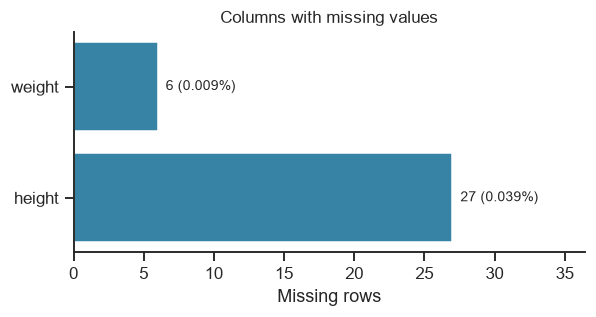

In [5]:
with_gaps = quality[quality["missing_n"] > 0]

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(with_gaps.index, with_gaps["missing_n"], color="#3783a5")
for y, (n, p) in enumerate(zip(with_gaps["missing_n"], with_gaps["missing_pct"])):
    ax.text(n, y, f"  {n} ({p:.3f}%)", va="center", fontsize=9)
ax.set(title="Columns with missing values", xlabel="Missing rows")
ax.set_xlim(0, with_gaps["missing_n"].max() * 1.35)
plt.show()

Duplicate rows are **kept**: identical recorded attributes do not by themselves mean the record is wrong. The few missing heights and weights are left as they are for now (they come from the cleaning step).

In [6]:
# Working copy used for all class comparisons.
df = data.dropna(subset=[TARGET]).copy()
print("Rows without a target label:", len(data) - len(df))

assert np.isfinite(df[NUMERIC].to_numpy(dtype=float)[~df[NUMERIC].isna().to_numpy()]).all()

df["target_name"] = df[TARGET].map(CLASS_NAMES)
CLASSES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES)]
COLORS = dict(zip(CLASSES, sns.color_palette("colorblind", len(CLASSES))))

for c in CATEGORICAL:
    df[c] = df[c].astype("string").fillna("<Missing>")
LEVELS = {c: df[c].value_counts().index.tolist() for c in CATEGORICAL}

print(f"Analysis population: {len(df):,} rows")

Rows without a target label: 0
Analysis population: 68,666 rows


In [7]:
def make_grid(n, ncols=3, cell=(4.6, 3.6)):
    """Create an n-panel figure and return a flat list of axes."""
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(cell[0] * ncols, cell[1] * nrows),
                             squeeze=False, constrained_layout=True)
    flat = list(axes.ravel())
    for extra in flat[n:]:
        extra.set_visible(False)
    return fig, flat[:n]

## 3. Target balance

,rows,percent
target_name,,
No disease,34697,50.53
Disease,33969,49.47


Always predicting the majority class gives 50.53% accuracy (baseline only).


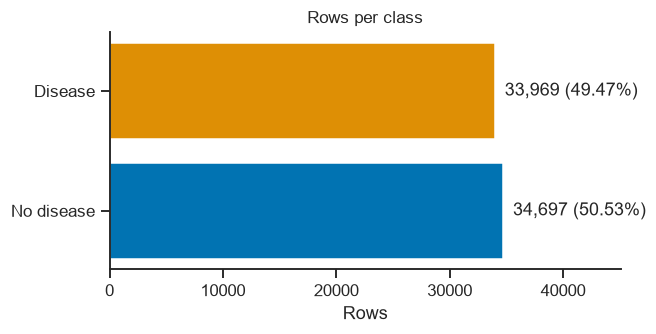

In [8]:
balance = df["target_name"].value_counts().reindex(CLASSES).to_frame("rows")
balance["percent"] = balance["rows"] / balance["rows"].sum() * 100
display(balance)

baseline = balance["rows"].max() / len(df)
print(f"Always predicting the majority class gives {baseline:.2%} accuracy (baseline only).")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(balance.index, balance["rows"], color=[COLORS[c] for c in balance.index])
for y, (n, p) in enumerate(zip(balance["rows"], balance["percent"])):
    ax.text(n, y, f"  {n:,} ({p:.2f}%)", va="center")
ax.set(title="Rows per class", xlabel="Rows")
ax.set_xlim(0, balance["rows"].max() * 1.3)
plt.show()

## 4. Single-feature views

### 4.1 Numeric features

In [9]:
display(df[NUMERIC].describe().T)

most_common = pd.DataFrame({
    "top_value": [df[c].mode().iloc[0] for c in NUMERIC],
    "top_value_share_pct": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in NUMERIC],
}, index=NUMERIC)
display(most_common)

,count,mean,std,min,25%,50%,75%,max
age_years,68666.0,53.29,6.76,29.6,48.3,53.9,58.4,64.9
height,68639.0,164.39,7.98,100.0,159.0,165.0,170.0,207.0
weight,68660.0,74.12,14.32,30.0,65.0,72.0,82.0,200.0
ap_hi,68666.0,126.67,16.68,70.0,120.0,120.0,140.0,240.0
ap_lo,68666.0,81.30,9.42,40.0,80.0,80.0,90.0,150.0


,top_value,top_value_share_pct
age_years,56.0,1.10
height,165.0,8.38
weight,65.0,5.52
ap_hi,120.0,40.28
ap_lo,80.0,50.59


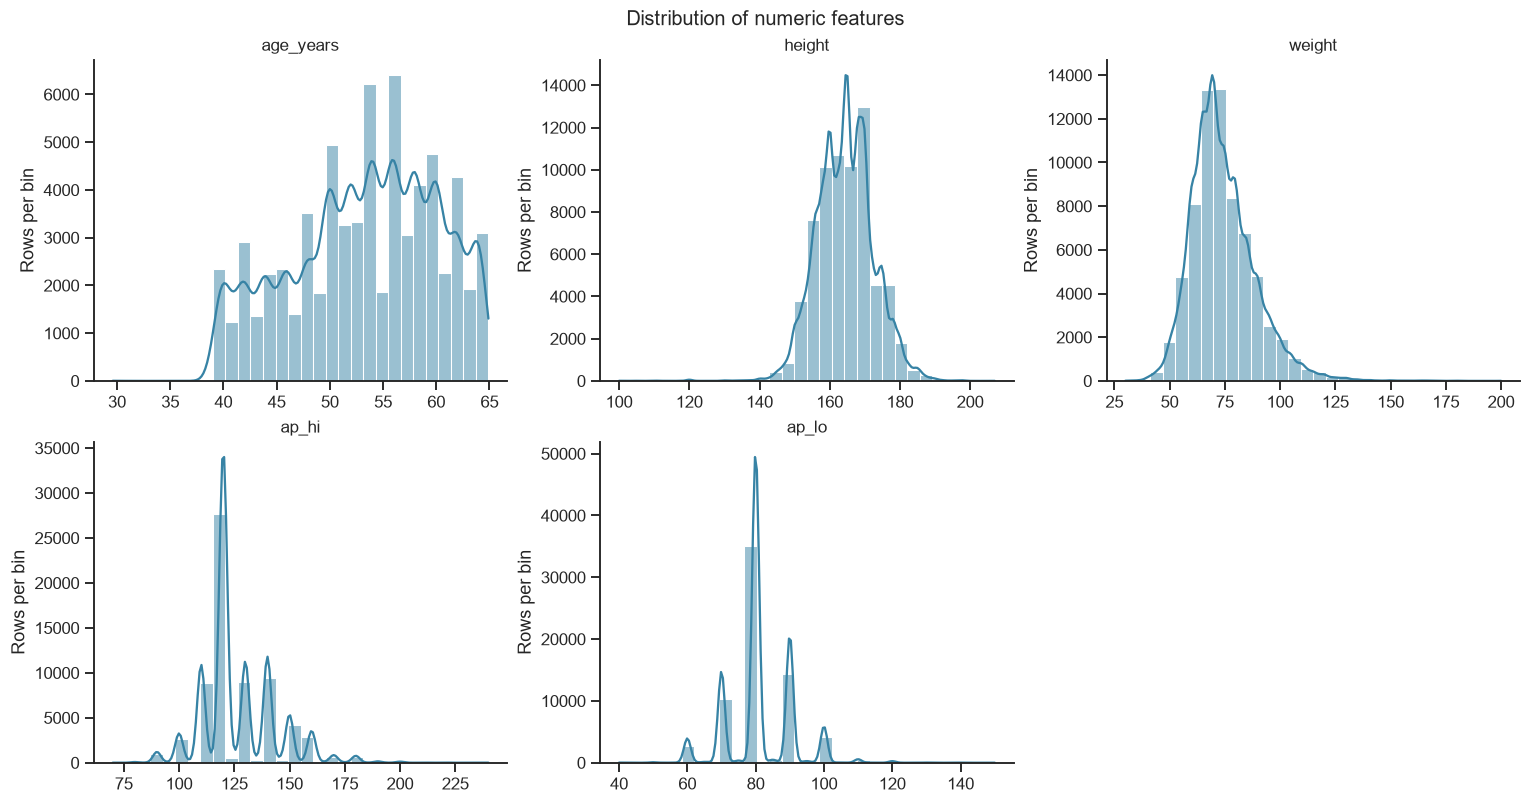

In [10]:
fig, axes = make_grid(len(NUMERIC))
for ax, col in zip(axes, NUMERIC):
    sns.histplot(df[col], bins=30, kde=True, color="#3783a5", ax=ax)
    ax.set(title=col, xlabel="", ylabel="Rows per bin")
fig.suptitle("Distribution of numeric features", fontsize=13)
plt.show()

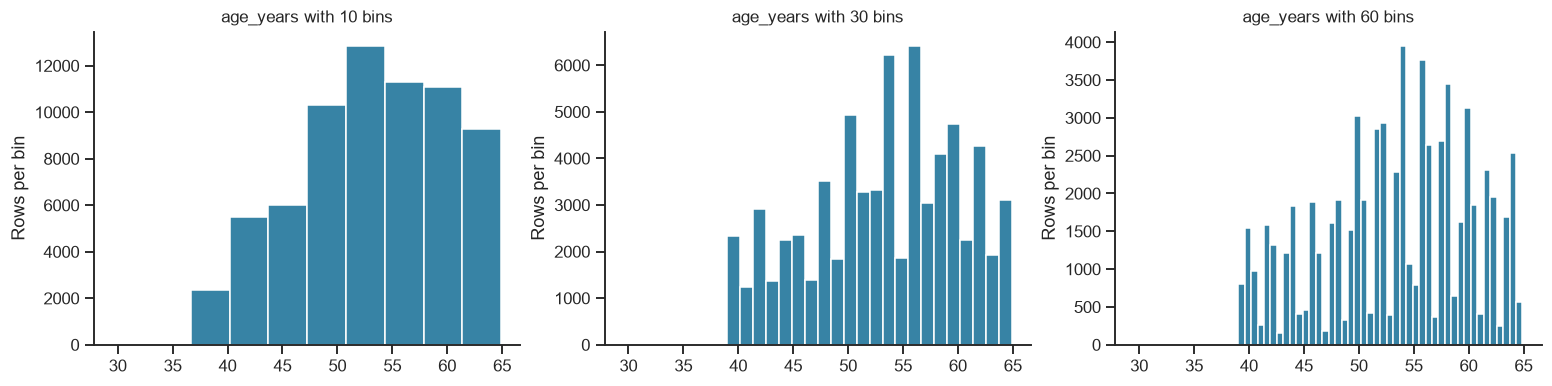

In [11]:
# Does the bin count change the story? (age_years as the example)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharex=True, constrained_layout=True)
for ax, n_bins in zip(axes, (10, 30, 60)):
    ax.hist(df["age_years"], bins=n_bins, color="#3783a5", edgecolor="white")
    ax.set(title=f"age_years with {n_bins} bins", ylabel="Rows per bin")
plt.show()

### 4.2 Categorical features

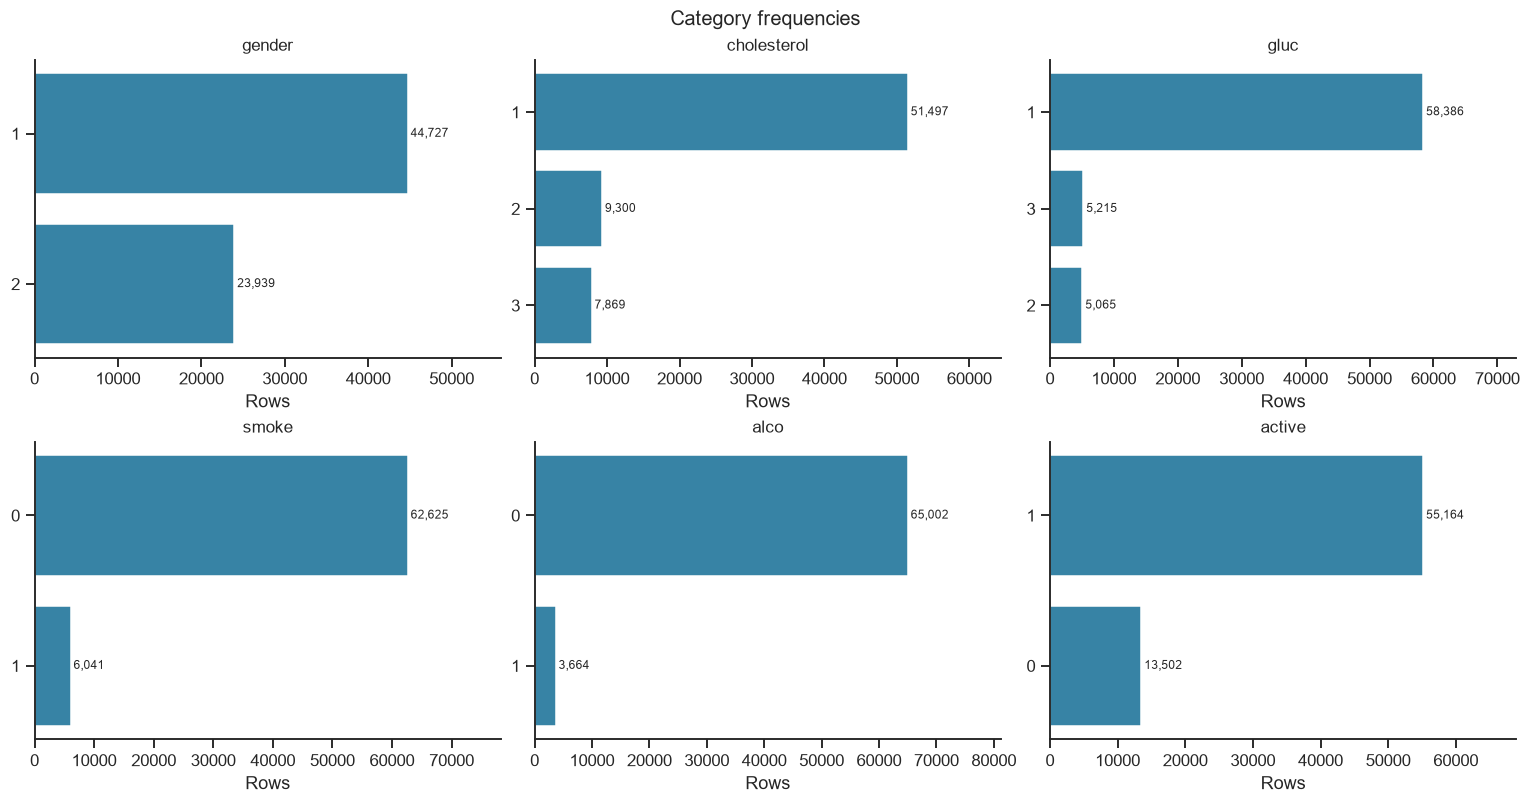


gender


,rows
gender,
1,44727
2,23939



cholesterol


,rows
cholesterol,
1,51497
2,9300
3,7869



gluc


...

,rows
smoke,
0,62625
1,6041



alco


,rows
alco,
0,65002
1,3664



active


,rows
active,
1,55164
0,13502


In [12]:
fig, axes = make_grid(len(CATEGORICAL))
for ax, col in zip(axes, CATEGORICAL):
    counts = df[col].value_counts().reindex(LEVELS[col])
    ax.barh(counts.index.astype(str), counts.values, color="#3783a5")
    for y, n in enumerate(counts.values):
        ax.text(n, y, f" {n:,}", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, counts.max() * 1.25)
    ax.set(title=col, xlabel="Rows")
fig.suptitle("Category frequencies", fontsize=13)
plt.show()

for col in CATEGORICAL:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).rename("rows").to_frame())

### 4.3 Outliers (Tukey fences)

In [13]:
def tukey_summary(series, k=1.5):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    spread = q3 - q1
    low, high = q1 - k * spread, q3 + k * spread
    hit = (s < low) | (s > high)
    return {"Q1": q1, "Q3": q3, "IQR": spread,
            "lower_fence": low, "upper_fence": high,
            "flagged_n": int(hit.sum()), "observed_n": len(s),
            "flagged_pct": hit.mean() * 100}

fences = pd.DataFrame({c: tukey_summary(df[c]) for c in NUMERIC}).T
fences.index.name = "feature"
display(fences)
print("Flagged rows are retained: an outlier is not automatically an error.")

,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n,observed_n,flagged_pct
feature,,,,,,,,
age_years,48.3,58.4,10.1,33.15,73.55,4.0,68666.0,5.83e-03
height,159.0,170.0,11.0,142.50,186.50,478.0,68639.0,6.96e-01
weight,65.0,82.0,17.0,39.50,107.50,1739.0,68660.0,2.53e+00
ap_hi,120.0,140.0,20.0,90.00,170.00,1005.0,68666.0,1.46e+00
ap_lo,80.0,90.0,10.0,65.00,105.00,3499.0,68666.0,5.10e+00


Flagged rows are retained: an outlier is not automatically an error.


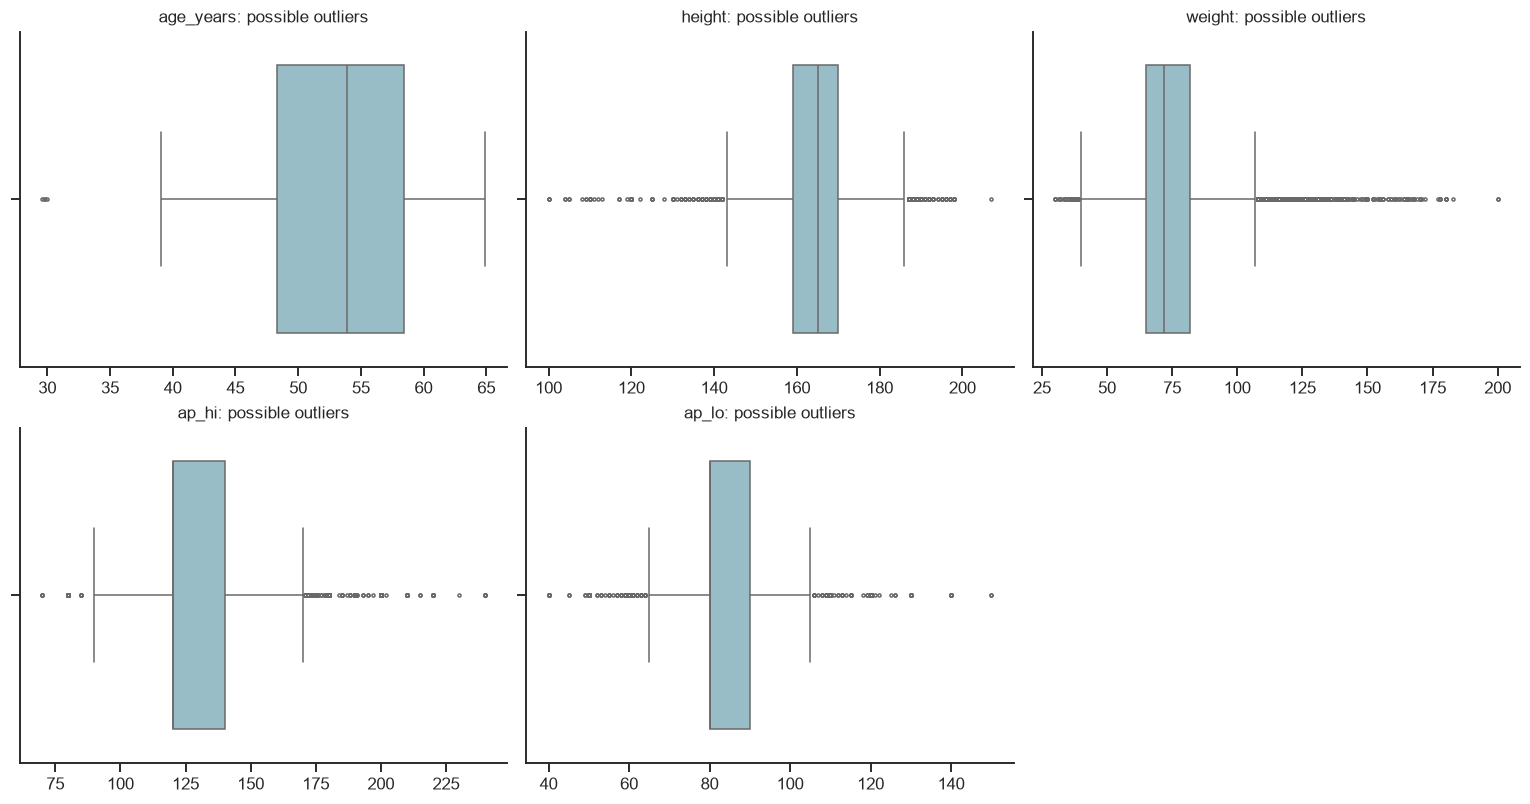

In [14]:
fig, axes = make_grid(len(NUMERIC))
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(x=df[col], color="#91c2ce", fliersize=2, ax=ax)
    ax.set(title=f"{col}: possible outliers", xlabel="")
plt.show()

## 5. Features versus target

### 5.1 Numeric features by class

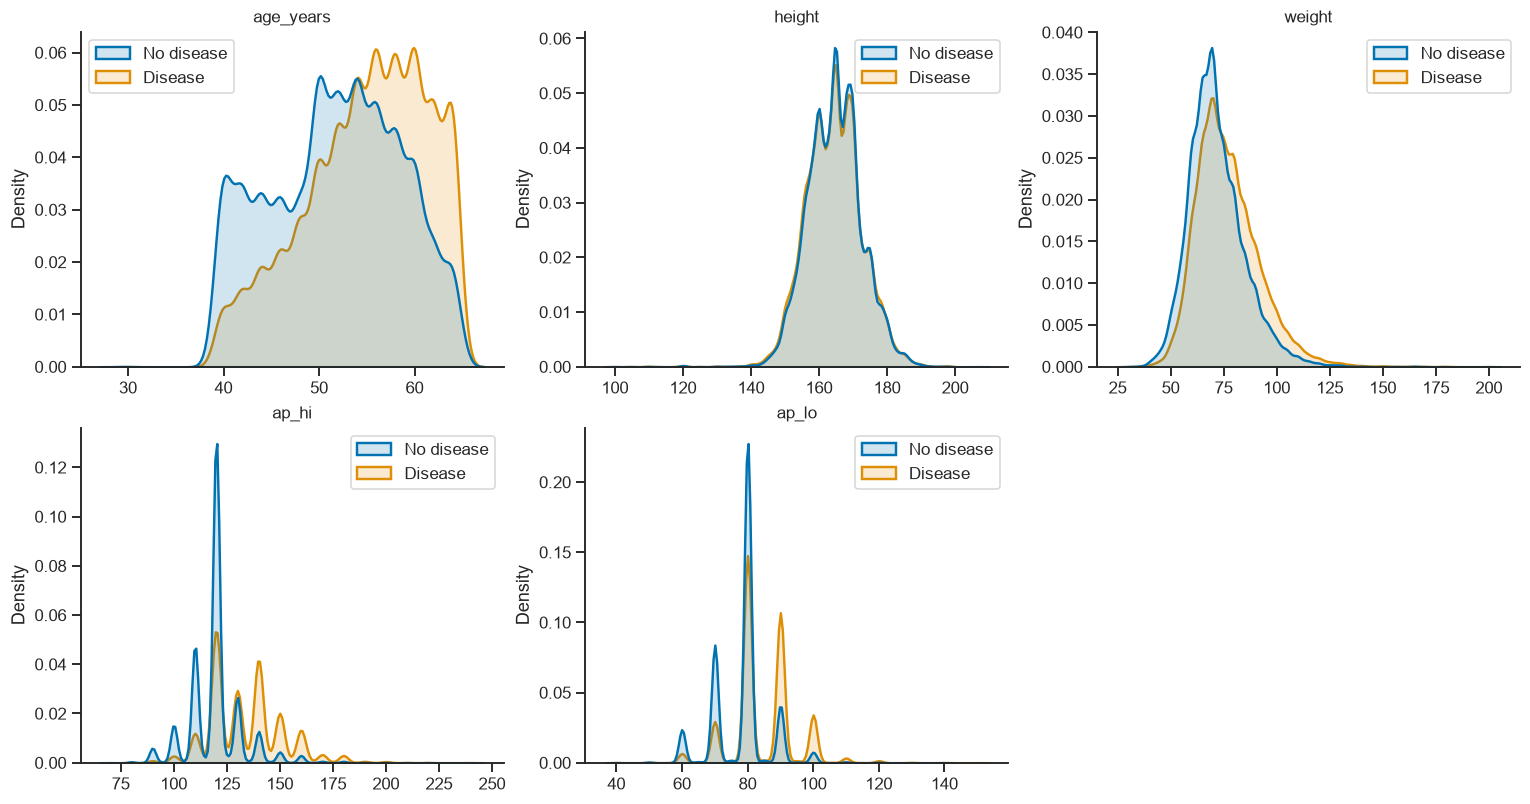

In [15]:
# Per-class density curves (each class integrates to 1, so size differences do not matter)
fig, axes = make_grid(len(NUMERIC))
for ax, col in zip(axes, NUMERIC):
    sns.kdeplot(data=df, x=col, hue="target_name", hue_order=CLASSES,
                palette=COLORS, common_norm=False, fill=True, alpha=0.18,
                linewidth=1.6, ax=ax)
    ax.set(title=col, xlabel="", ylabel="Density")
    if ax.get_legend():
        ax.get_legend().set_title("")
plt.show()

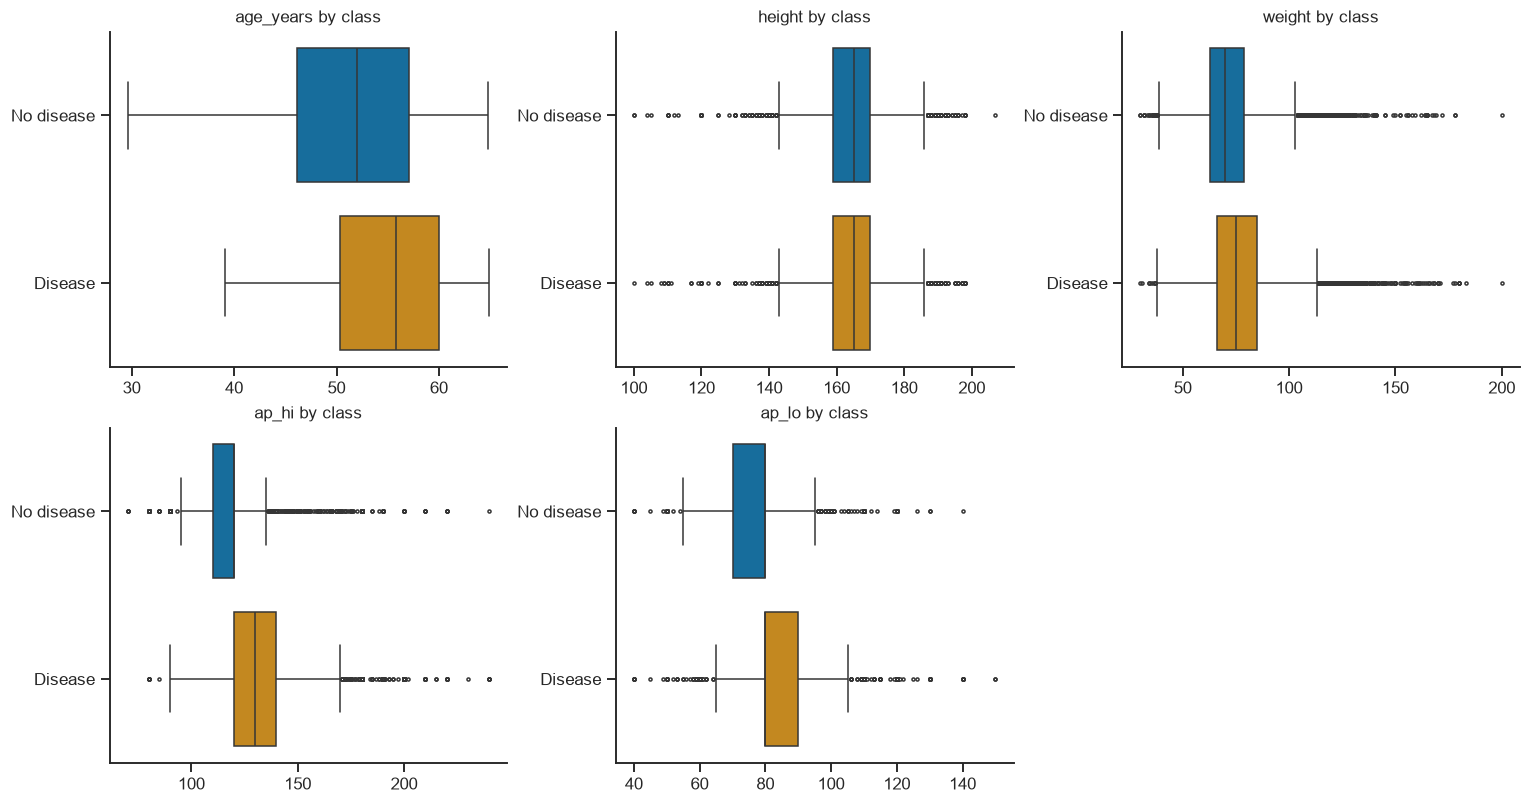

median                IQR        
target_name No disease Disease No disease Disease
age_years         52.0    55.8       11.0     9.7
height           165.0   165.0       11.0    11.0
weight            70.0    75.0       16.0    19.0
ap_hi            120.0   130.0       10.0    20.0
ap_lo             80.0    80.0       10.0    10.0

In [16]:
fig, axes = make_grid(len(NUMERIC))
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(data=df, y="target_name", x=col, order=CLASSES, hue="target_name",
                palette=COLORS, legend=False, fliersize=2, orient="h", ax=ax)
    ax.set(title=f"{col} by class", ylabel="", xlabel="")
plt.show()

median_table = df.groupby("target_name")[NUMERIC].median().reindex(CLASSES).T
iqr_table = df.groupby("target_name")[NUMERIC].agg(lambda s: s.quantile(.75) - s.quantile(.25)).reindex(CLASSES).T
display(pd.concat({"median": median_table, "IQR": iqr_table}, axis=1))

target_name No disease               Disease              
                  mean    min    max    mean    min    max
age_years        51.69   29.6   64.8   54.93   39.1   64.9
height          164.49  100.0  207.0  164.30  100.0  198.0
weight           71.57   30.0  200.0   76.73   30.0  200.0
ap_hi           119.60   70.0  240.0  133.89   80.0  240.0
ap_lo            78.12   40.0  140.0   84.55   40.0  150.0

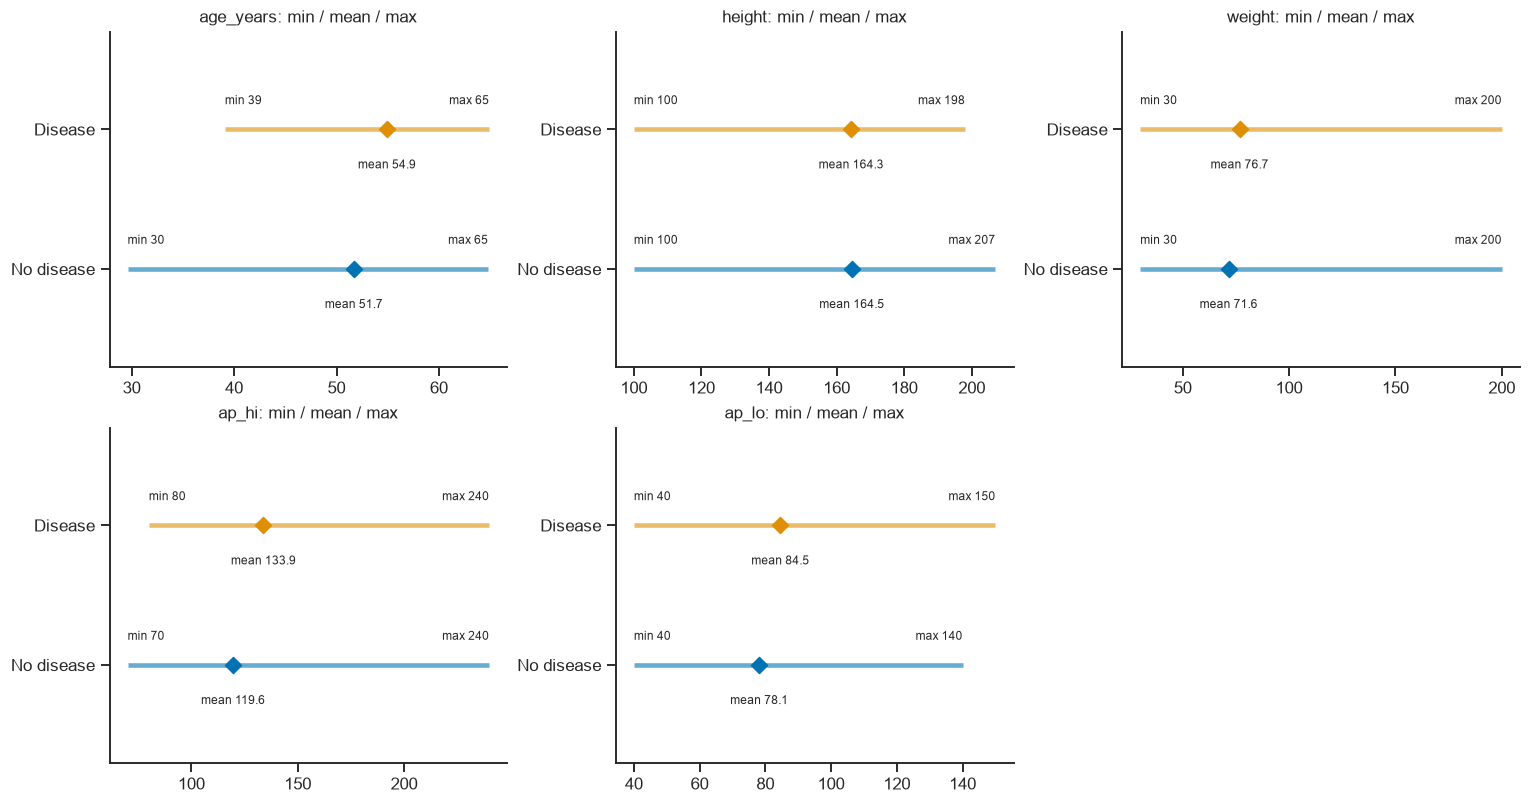

In [17]:
# Mean, minimum and maximum per class
agg = df.groupby("target_name")[NUMERIC].agg(["mean", "min", "max"]).reindex(CLASSES)
display(agg.T.unstack(level=1))

fig, axes = make_grid(len(NUMERIC))
for ax, col in zip(axes, NUMERIC):
    for y, cls in enumerate(CLASSES):
        lo, mu, hi = agg.loc[cls, (col, "min")], agg.loc[cls, (col, "mean")], agg.loc[cls, (col, "max")]
        ax.hlines(y, lo, hi, color=COLORS[cls], linewidth=3, alpha=0.6)
        ax.scatter(mu, y, marker="D", s=55, color=COLORS[cls], zorder=3)
        ax.text(lo, y + 0.18, f"min {lo:.0f}", fontsize=8, ha="left")
        ax.text(hi, y + 0.18, f"max {hi:.0f}", fontsize=8, ha="right")
        ax.text(mu, y - 0.28, f"mean {mu:.1f}", fontsize=8, ha="center")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_ylim(-0.7, len(CLASSES) - 0.3)
    ax.set(title=f"{col}: min / mean / max")
plt.show()

### 5.2 Categorical features by class

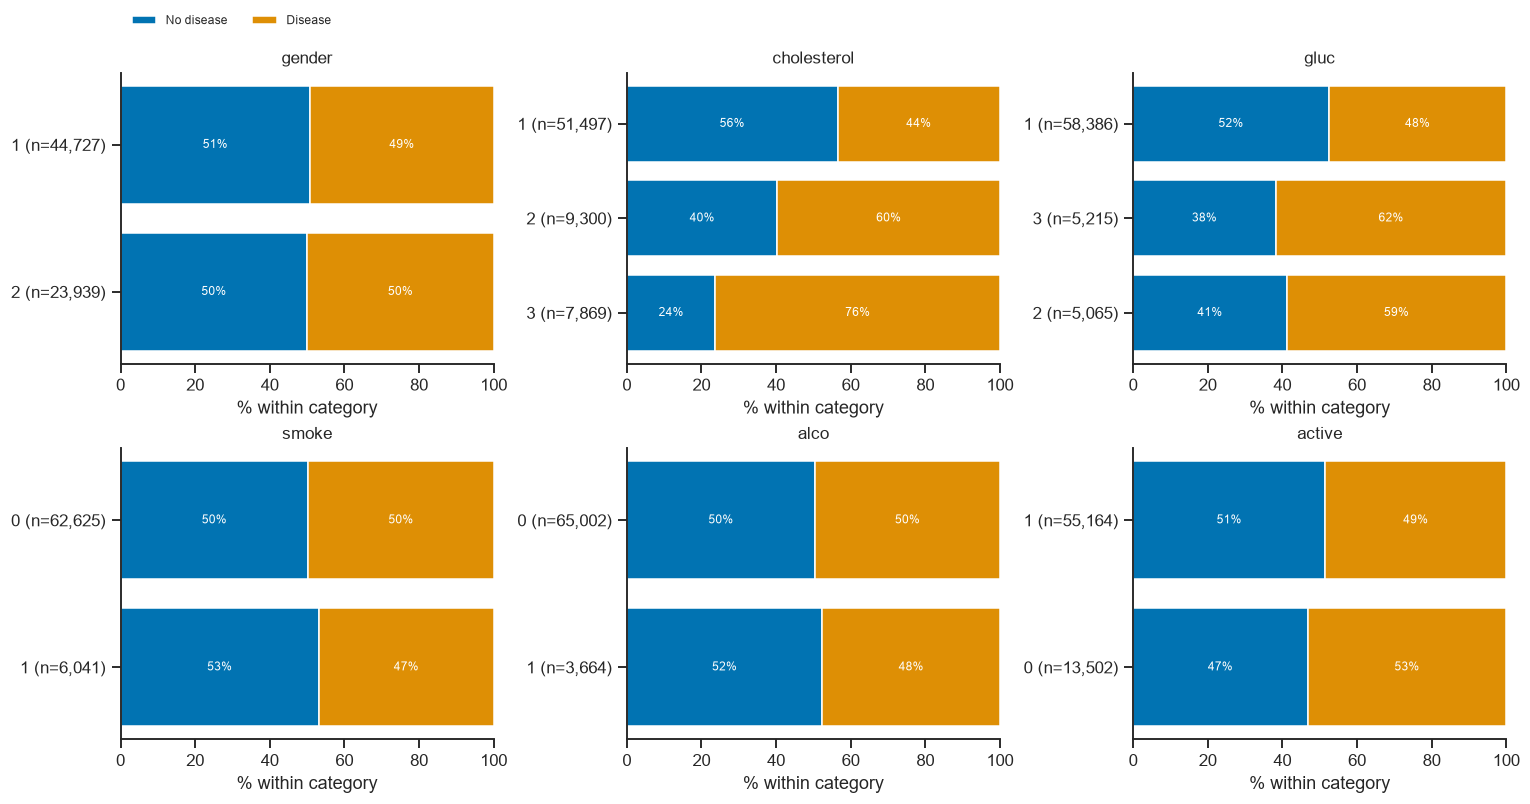


gender: class share within each category (%)


target_name,No disease,Disease,n,small
gender,,,,
1,50.79,49.21,44727,False
2,50.05,49.95,23939,False



cholesterol: class share within each category (%)


target_name,No disease,Disease,n,small
cholesterol,,,,
1,56.46,43.54,51497,False
2,40.37,59.63,9300,False
3,23.74,76.26,7869,False



gluc: class share within each category (%)


...

target_name,No disease,Disease,n,small
smoke,,,,
0,50.28,49.72,62625,False
1,53.15,46.85,6041,False



alco: class share within each category (%)


target_name,No disease,Disease,n,small
alco,,,,
0,50.43,49.57,65002,False
1,52.37,47.63,3664,False



active: class share within each category (%)


target_name,No disease,Disease,n,small
active,,,,
1,51.46,48.54,55164,False
0,46.75,53.25,13502,False


In [18]:
fig, axes = make_grid(len(CATEGORICAL))
share_tables = {}
for ax, col in zip(axes, CATEGORICAL):
    counts = pd.crosstab(df[col], df["target_name"]).reindex(index=LEVELS[col], columns=CLASSES, fill_value=0)
    n_per_level = counts.sum(axis=1)
    shares = counts.div(n_per_level, axis=0) * 100
    share_tables[col] = shares.assign(n=n_per_level, small=n_per_level < MIN_GROUP)

    left = np.zeros(len(shares))
    for cls in CLASSES:
        ax.barh(range(len(shares)), shares[cls], left=left, color=COLORS[cls],
                label=cls, edgecolor="white")
        for y, (start, w) in enumerate(zip(left, shares[cls])):
            ax.text(start + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=8, color="white")
        left += shares[cls].to_numpy()
    ax.set_yticks(range(len(shares)),
                  [f"{lvl} (n={n:,})" for lvl, n in n_per_level.items()])
    ax.invert_yaxis()
    ax.set(title=col, xlabel="% within category", xlim=(0, 100))
axes[0].legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.12), ncol=2, frameon=False)
plt.show()

for col, tab in share_tables.items():
    print(f"\n{col}: class share within each category (%)")
    display(tab.round(2))

In [19]:
# Per-class counts (absolute numbers behind the percentages)
for col in CATEGORICAL:
    print(f"\n{col}: rows per class")
    display(pd.crosstab(df[col], df["target_name"]).reindex(LEVELS[col])[CLASSES])


gender: rows per class


target_name,No disease,Disease
gender,,
1,22716,22011
2,11981,11958



cholesterol: rows per class


target_name,No disease,Disease
cholesterol,,
1,29075,22422
2,3754,5546
3,1868,6001



gluc: rows per class


...

target_name,No disease,Disease
smoke,,
0,31486,31139
1,3211,2830



alco: rows per class


target_name,No disease,Disease
alco,,
0,32778,32224
1,1919,1745



active: rows per class


target_name,No disease,Disease
active,,
1,28385,26779
0,6312,7190


## 6. Summary of findings

**Data quality.** 33 missing values (27 in `height`, 6 in `weight`) and 24 repeated rows. No constant columns. Duplicates are kept because identical attributes do not prove a faulty record.

**Target.** Nearly balanced: 50.53% no disease vs 49.47% disease. A majority-class guess scores 50.53%, which is only a baseline.

**Numeric features.** All five show possible outliers under the 1.5 x IQR rule; a few very low ages are flagged too. Outliers are retained until their plausibility is reviewed.

**Numeric vs target.**
- `age_years`: disease cases are concentrated at older ages (median about 56 vs 52 years; mean about 55 vs 51; minimum about 39 vs 29; same maximum, about 65).
- `ap_hi`, `ap_lo`: strongest separation. The no-disease class sits around 120 / 80, the disease class shifts higher with a wider IQR. Both classes reach maxima around 240 / 150.
- `weight`: heavy overlap, with a slight upward shift for disease (mean about 76 vs 71 kg). Min 30 kg and max 200 kg in both classes.
- `height`: practically identical in both classes (mean about 164 cm), so it barely separates them.

**Categorical vs target.**
- `cholesterol` and `gluc` carry clear signal; at cholesterol level 3 the disease share reaches about 76%.
- `gender`, `smoke`, `alco`: close to 50% in every category, so little discriminative power on their own.
- `active = 0` has a slightly higher disease share (about 53%).